# Классические методы компьютерного зрения. Отображение и работа с видео в Open CV

*Примечание*. Частично использованы материалы Кирилла Овчинникова

Теперь перейдем к обработке данных из оцифрованного видео. На практике в системах с компьютерным зрением графическая информация поступает
видеопотоком — в виде сплошной последовательности изображений
(кадров). Источником видеоданных может быть видеокамера, которая осуществляет съемку в реальном времени, или видеофайл, в который эти данные были предварительно записаны. (В наших задачах мы будем пользоваться данными с обычной web-камеры или из видео файла форматов **.avi** и/или **.mp4**).

## Отображение видеоданных с web-камеры



In [2]:
import cv2 # импорт Open CV
# from google.colab.patches import cv2_imshow # cv2_imshow служит для отображения картинок в Google Colab
import numpy as np
import os
import matplotlib.pyplot as plt

%matplotlib inline

Рассмотрим программу отображения видео в режиме захвата видеопотока с web-камеры в Open CV, установленном на компьютере (ноутбуке). Ниже приведен пример программного кода отображения видео с web-камеры:

In [1]:
import cv2
capImg = cv2.VideoCapture(0) # связываем видеопоток камеры с переменной capImg
# запускаем бесконечный цикл, чтобы следить в реальном времени
while(True):
  # получаем кадр из видеопотока, кадры по очереди считываются в переменную frame
  ret, frame = capImg.read()
  cv2.imshow('Video', frame) # показываем кадр в окне ’Video’
  # организуем выход из цикла по нажатию клавиши,
  # ждем 30 миллисекунд нажатие, записываем код нажатой клавиши
  key_press = cv2.waitKey(30)
  # если код нажатой клавиши совпадает с кодом «q»(quit - выход),
  if key_press == ord('q'): #то прервать цикл while
    break
capImg.release() # освобождаем память от переменной capImg
cv2.destroyAllWindows() # закрываем все окна opencv

QFontDatabase: Cannot find font directory /home/ruslan/projects/asu/venv/lib/python3.14/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/ruslan/projects/asu/venv/lib/python3.14/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/ruslan/projects/asu/venv/lib/python3.14/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/ruslan/projects/asu/venv/lib/python3.14/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font director

Вначале, как обычно, импортируется модуль OpenCV,
затем с помощью функции **cv2.VideoCapture(0)** видеоданные
связываются с переменной `capImg`. Значение «0» в аргументе функции обозначает номер подключенной камеры. Нумерация начинается
с нуля. Далее запускается бесконечный цикл, где полученные из видеопотока кадры (frame) отображаются в окне «Video» с помощью
функции **cv2.imshow()**. Завершение работы программы осуществляется по нажатию определенной клавиши c помощью функции **cv2.waitKey()**. **Но в Google Colab этот код работать не будет.**

Попробуем всё же получить доступ к веб-камере из Google Colab. Следующий код взят отсюда: https://colab.research.google.com/notebooks/snippets/advanced_outputs.ipynb#scrollTo=Camera_Capture - здесь вообще есть несколько интересных примеров взаимодействия Python и JavaScript в Colab. Выполним:

In [2]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


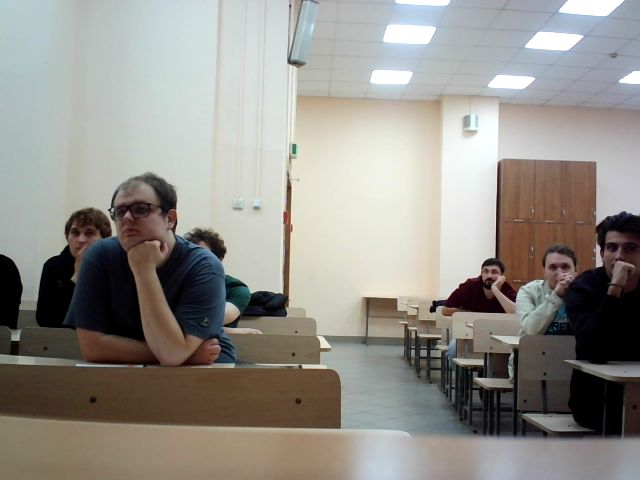

In [3]:
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

In [4]:
!ls

photo.jpg  sample_data


## Отображение видеоданных из файла

Теперь перейдем к отображению видео из файла на компьютере с установленным Open CV. Для нашего случая подойдет любой небольшой видеофайл, полученный с помощью смартфона или цифровой камеры.

In [25]:
import cv2
# связываем файл video.avi с переменной capImg
capImg = cv2.VideoCapture('vid.mp4')
# открываем в цикле файл
while(capImg.isOpened()):
  # получаем кадр из видеопотока файла
  # кадры по очереди считываются в переменную frame
  ret, frame = capImg.read()
  # если кадры закончились
  if frame is None:
    break # прерываем работу цикла
  # показываем кадр из файла в окне video_file
  cv2.imshow("video_file", frame)
  # организуем выход из цикла по нажатию клавиши, ждем 30 миллисекунд нажатия, записываем код нажатой клавиши
  key_press = cv2.waitKey(30)
  # если код нажатой клавиши совпадает с кодом «q»,
  if key_press == ord('q'):
    break # то прервать цикл while
capImg.release()# освобождаем память от переменной capImg
cv2.destroyAllWindows()# закрываем все окна opencv

Как видно из программного кода, для открытия видеофайла используется та же функция **cv2.VideoCapture()**. Однако в качестве аргумента функции используется непосредственно имя видеофайла или полный путь до него, если видеофайл находится в другой
папке. Далее, так же как и с web-камерой, считываем покадрово
данные из видеопотока. Если кадры закончились, прерываем работу
цикла. **Но в Google Colab этот код опять работать не будет.** Для отображения видео в Colab сделаем так:

Загрузка файлов в Google Colab

In [5]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('Файл(ы) "{name}" размером {length} байт загружен(ы)'.format(
      name=fn, length=len(uploaded[fn])))

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
video_path = 'vid.mp4'

In [8]:
from IPython.display import HTML
from base64 import b64encode
mp4 = open(video_path,'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

Теперь выполним встраивание видео в html-страницу Google Colab шириной 1000 пикселей.

In [6]:
!ls

vid.mp4	 Лекция_4_Компьютерное_зрение_работа_с_видео.ipynb


In [ ]:
HTML("""
<video width=1000 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

Прежде чем обрабатывать видео, полезно узнать его характеристики: частоту кадров (FPS), разрешение, общее количество кадров. Эти данные можно получить через методы объекта cv2.VideoCapture.

FPS:        23.37
Размер:     1920 x 1080
Кадров:     177
Длительность: 7.57 сек


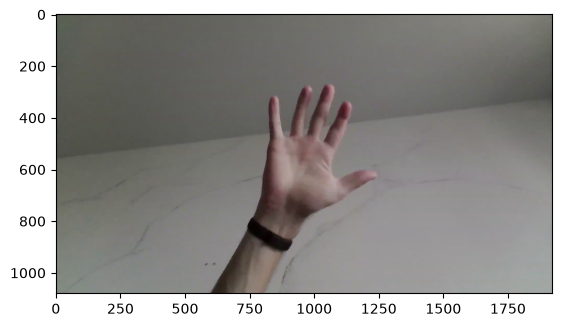

In [13]:
cap = cv2.VideoCapture(video_path)

# Свойства видеофайла
fps      = cap.get(cv2.CAP_PROP_FPS)
width    = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = n_frames / fps if fps > 0 else 0

print(f'FPS:        {fps:.2f}')
print(f'Размер:     {width} x {height}')
print(f'Кадров:     {n_frames}')
print(f'Длительность: {duration:.2f} сек')

# Извлечение конкретного кадра (например, 36-го)
frame_n = 36
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_n)
ret, frame = cap.read()
if ret:
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

cap.release()

## Поиск цветных объектов на видео с помощью OpenCV

Мы с вами уже находили цветные объекты на фотографиях.
При этом, кроме самого объекта, обнаруживалось большое количество мелких крапинок, которые не являются искомым объектом. Чтобы таких крапинок было поменьше, мы исключим из поиска те области, где искомый объект визуально не присутствует, то есть поиск будем проводить внутри границ некоторой области
кадра. Для этого предварительно просмотрим видео и определим
границы и размеры области, в которой присутствуют интересующие нас искомые объекты. В нашем примере это изображения дорожных знаков. Приблизительную оценку расположения и размеров нашей области поиска можно сделать с учетом того, что левый верхний угол кадра имеет координаты (0, 0), а правый
нижний — это значения размеров кадра. Окончательные размеры области подберем опытным путем. Cоставим порядок действий для поиска цветного
объекта в видеопотоке:
1. Получить доступ к графическим данным видеопотока: открытие
видеофайла или захват с видеокамеры.
2. Перевести изображение кадра в цветовое HSV-пространство.
3. Провести обрезку кадра по размерам видимой области с искомым объектом.
4. Подобрать границы цветового диапазона для цветовой маски.
5. Применить цветовую HSV-маску к кадрам видеопотока, переведенным в HSV-пространство.
6. Отобразить результаты наложения цветовой HSV-маски в отдельном окне.

Реализуем приведенный выше алгоритм. Мы будем находить объекты синего
цвета (дорожные знаки на синем фоне) в видеопоследовательности из файла, полученного с автомобильного видеорегистратора.

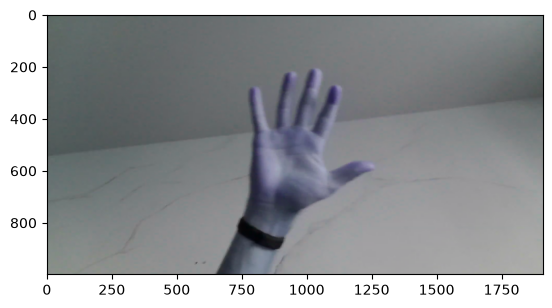

In [4]:
capImg = cv2.VideoCapture(video_path)  # связываем видеопоток файла с переменной capImg
count = 0

while capImg.isOpened():  # открываем файл с видео
    count += 1
    ret, frame = capImg.read()  # получаем кадр из видеопотока файла, кадры по очереди считываются в переменную frame
    if frame is None or count > 100:  # если кадры закончились, то прерываем цикл
        break

    frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)  # переводим кадр в цветовое HSV-пространство
    crop_frame = frame[1:1000, 1:1910]  # делаем вырезку области кадра, где ожидается объект
    crop_frame_hsv = frame_hsv[200:470, 550:850]

    # задаем нижнюю и верхнюю границы цветового фильтра с помощью массивов numpy
    # цвет 0...180,
    # насыщенность 0 – блеклый, 255 - насыщенный
    # яркость 0 – темный, 255 - светлый
    low_Blue  = np.array([105, 150, 0],   dtype="uint8")
    high_Blue = np.array([135, 255, 210], dtype="uint8")

    # применяем маску по цвету к фрагменту кадра
    blue_mask = cv2.inRange(crop_frame_hsv, low_Blue, high_Blue)

    # показываем области кадров с объектом
    # результат наложения маски
    # и вырезку из кадра
    # print(f'--- Кадр {count} ---')
    plt.imshow(blue_mask)
    plt.imshow(crop_frame)

    # ВАЖНО: в Google Colab обработка нажатий клавиш (cv2.waitKey) и работа
    # с GUI-окнами (cv2.imshow, cv2.destroyAllWindows) не поддерживаются.

# освобождаем память от переменной capImg
capImg.release()
# закрываем все окна opencv — в Colab эта функция не нужна и не работает
# cv2.destroyAllWindows()

Для наглядности сделаем отображение кадра и маски рядом

In [ ]:
import cv2, numpy as np, time
from IPython.display import display, Image

capImg = cv2.VideoCapture(video_path)

count = 0
while capImg.isOpened():
    count += 1
    ret, frame = capImg.read()
    if frame is None or count > 50:
        break

    frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    crop_frame = frame[200:470, 550:850]
    crop_frame_hsv = frame_hsv[200:470, 550:850]

    low_Blue  = np.array([105, 150, 0],   dtype="uint8")
    high_Blue = np.array([135, 255, 210], dtype="uint8")
    blue_mask = cv2.inRange(crop_frame_hsv, low_Blue, high_Blue)

    # Склеиваем маску и кадр в одно изображение для наглядности
    mask_bgr = cv2.cvtColor(blue_mask, cv2.COLOR_GRAY2BGR)
    combined = np.hstack([crop_frame, mask_bgr])

    # Кодируем в JPEG и выводим
    _, jpg = cv2.imencode('.jpg', combined)
    display(Image(data=jpg.tobytes(), width=600))
    time.sleep(0.05)

capImg.release()

После конвертации кадров в HSV-пространство с помощью функции **cv2.cvtColor()** выполняем обрезку кадров по границам области, в которой будет размещен искомый объект. Выделив такую область в кадре, мы значительно уменьшаем или даже исключаем нахождение ложных объектов — групп точек, не являющихся объектом. Далее подбираем нижнюю и верхнюю границы цветового фильтра **low_Blue** и **high_Blue** так, чтобы получить предельно четкое изображение объекта на черном фоне.

## Суммирование цветовых масок



Рассмотрим задачу поиска нескольких объектов, различающихся по цветам.
Для этого необходимо определить цветовую маску каждого объекта. Затем полученные маски сложить и наложить их на исходное изображение. В результате
мы получим составной цветовой фильтр, который позволит отобразить искомую группу объектов. Давайте разберем работу программы,
которая в потоке видео находит группы объектов красного, желтого
и синего цветов.

In [ ]:
capImg = cv2.VideoCapture(video_path)# связываем видеопоток файла с переменной capImg
count = 0
while(capImg.isOpened()):# открываем файл с видео
  count += 1
  ret, frame = capImg.read() # получаем кадр из видеопотока файла, кадры по очереди считываются в переменную frame
  if frame is None or count > 15:  # если кадры закончились, то прерываем цикл
    break
  frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)# переводим кадр в цветовое HSV-пространство
  crop_frame = frame[200:470, 550:850]  # делаем вырезку области кадра, где ожидается объект
  crop_frame_hsv = frame_hsv[200:470, 550:850]
  # задаем нижнюю и верхнюю границы цветового фильтра с помощью массивов numpy

  # цвет 0...180,
  # насыщенность 0 – блеклый, 255 - насыщенный
  # яркость 0 – темный, 255 - светлый

  low_Blue = np.array ([105, 150, 0],  dtype = "uint8") # фильтр для синего цвета
  high_Blue = np.array([135, 255, 210], dtype = "uint8")

  low_Yel = np.array([10, 150, 100], dtype = "uint8") # фильтр для желтого цвета
  high_Yel = np.array([50, 255, 255], dtype = "uint8")

  low_Red_O = np.array([0, 85, 110], dtype = "uint8")# фильтр для красного цвета
  high_Red_O = np.array([5, 165, 155], dtype = "uint8")# красный цвет представляет собой две области, красный в сторону оранжевой области
  low_Red_V = np.array([165, 55, 40], dtype = "uint8")# красный в сторону фиолетовой области
  high_Red_V = np.array([180, 105, 120], dtype = "uint8")

  blue_mask = cv2.inRange(crop_frame_hsv, low_Blue, high_Blue) # применяем маску по каждому цвету к фрагменту кадра для выделения синего цвета

  yel_mask = cv2.inRange(crop_frame_hsv, low_Yel, high_Yel) # для выделения желтого цвета

  red1_mask = cv2.inRange(crop_frame_hsv, low_Red_O, high_Red_O) # для выделения красного накладываются две маски
  red2_mask = cv2.inRange(crop_frame_hsv, low_Red_V, high_Red_V)

  full_mask = red1_mask + red2_mask + blue_mask + yel_mask # вычисляем полную маску - она представляет собой сумму всех масок

   # ВЫВОД РЕЗУЛЬТАТА
  print(f'--- Кадр {count} ---')
  cv2_imshow(full_mask)# результат наложения маски,
  cv2_imshow(crop_frame)# вырезка из кадра

Мы добавили несколько строк для определения границ фильтров желтого и красного цветов. Если фильтр для желтого цвета состоит из одной области с границами
**low_Yel** и **high_Yel**, то для красного цвета таких областей две. Границы этих областей в коде обозначены как **low_Red_O**, **high_Red_O** и **low_Red_V**, **high_Red_V**. Это объясняется тем, что красный цвет находится на границе шкалы H пространства **HSV**. Оттенки красного
цвета присутствуют в оранжевой и фиолетовой областях цветового пространства.


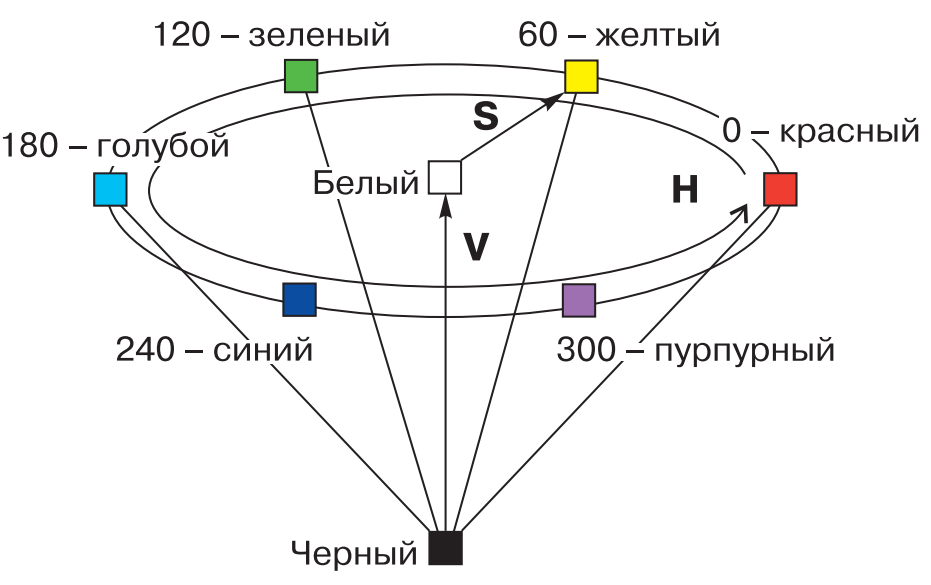

Поэтому фильтр для красного будет состоять из двух областей: в начале шкалы **H** — красно-оранжевая область и в конце шкалы **H** — фиолетово-красная область. Сложив все области, мы получим составной фильтр, условные границы областей которого изображены на цветовой диаграмме (Напомню, в OpenCV шкала для **H** кодируется от 0 до 180, а не до 360, как изображено на рисунке. Соответственно все значения параметра цвета из данного рисунка уменьшаются в два раза!)

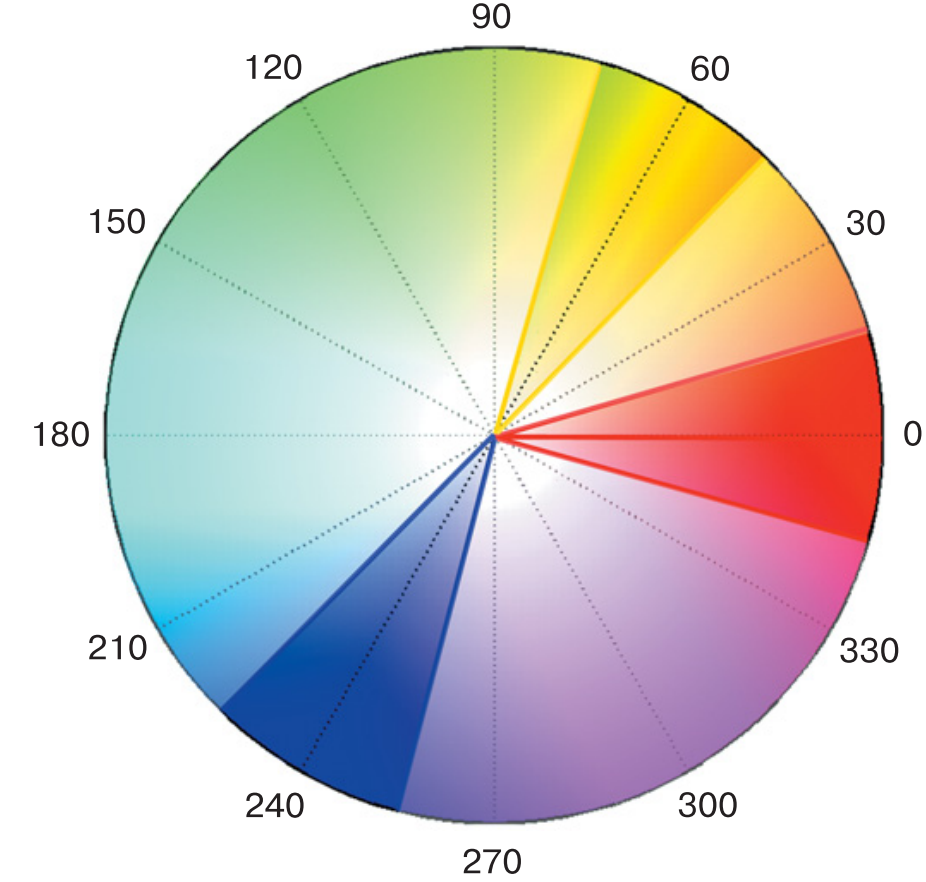

После того как были заданы все границы цветовых фильтров, получаем с помощью функции **cv2.inRange()** маску по каждому цвету применительно к нашему фрагменту кадра **crop_frame_hsv**. Результаты наложения масок (переменные **blue_mask**, **yel_mask**, **red1_mask**, **red2_mask**) суммируются и записываются в переменную **full_mask**.

При суммировании масок появляются также и ложные артефакты. Размеры некоторых пятен сопоставимы с размерами искомых объектов. А это может привести к определенным трудностям при идентификации нужных объектов. Чтобы избежать подобных проблем на данном этапе, необходимо осуществлять более локализованный поиск, то есть только в той области кадра, где действительно находится искомый объект или группа объектов. Для этого требуется выполнять срезы более тщательно.

## Морфологические операции: очистка масок от шума

В предыдущих примерах мы видели, что HSV-маски содержат много мелких «крапинок» — одиночных пикселей и небольших пятен. Это ложные срабатывания, которые мешают корректно находить объекты. Классический способ избавиться от шума — морфологические операции

In [ ]:
cap = cv2.VideoCapture(video_path)
count = 0
kernel = np.ones((5, 5), np.uint8)

while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if frame is None or count > 7:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    crop = frame[200:470, 550:850]
    crop_hsv = hsv[200:470, 550:850]

    low_blue  = np.array([105, 150, 0],  dtype='uint8')
    high_blue = np.array([135, 255, 210],dtype='uint8')
    mask = cv2.inRange(crop_hsv, low_blue, high_blue)

    # --- Морфологическая обработка ---
    mask_open  = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)   # убирает шум
    mask_close = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)   # заполняет дыры
    mask_clean = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel)

    print('Исходная маска | После OPEN | После CLOSE | OPEN + CLOSE')
    cv2_imshow(np.hstack([mask, mask_open, mask_close, mask_clean]))
    cv2_imshow(crop)

## Поиск контуров и ограничивающих рамок

После того как маска очищена, нужно найти сами объекты. Для этого используется функция cv2.findContours, которая возвращает список контуров (замкнутых кривых). Каждый контур можно:

* отфильтровать по площади (cv2.contourArea);

* описать ограничивающим прямоугольником (cv2.boundingRect);

* описать минимальным повёрнутым прямоугольником (cv2.minAreaRect);

* аппроксимировать многоугольником (cv2.approxPolyDP).

Такой подход позволяет не только находить объекты, но и вычислять их координаты — основу для дальнейшего трекинга.

In [ ]:
cap = cv2.VideoCapture(video_path)

# Пропускаем вступление — например, знаков в первых кадрах может не быть
for _ in range(30):
    cap.read()

count = 0
kernel = np.ones((3, 3), np.uint8)

while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if frame is None or count > 5:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # Обрезка
    x1, y1, x2, y2 = 550, 80, 1000, 470
    crop     = frame[y1:y2, x1:x2].copy()
    crop_hsv = hsv[y1:y2, x1:x2]

    # Диапазон синего
    low_blue  = np.array([100, 100, 100], dtype='uint8')
    high_blue = np.array([130, 255, 255], dtype='uint8')

    mask = cv2.inRange(crop_hsv, low_blue, high_blue)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    # --- ДИАГНОСТИКА: сколько пикселей осталось в маске ---
    nz = int(np.count_nonzero(mask))
    print(f'Кадр {count}: пикселей в маске = {nz}')

    # Если маска пустая — нечего искать, сразу идём к выводу
    if nz == 0:
        cv2_imshow(np.hstack([
            cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR),
            crop
        ]))
        continue

    # --- Поиск контуров ---
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    print(f'   Найдено контуров: {len(contours)}')
    print(f'   Площади: {[int(cv2.contourArea(c)) for c in contours]}')

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 40:               # порог снижен: было 300
            continue

        # Ограничивающий прямоугольник
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(crop, (x, y), (x + w, y + h), (0, 255, 0), 2)

        # Минимальный повёрнутый прямоугольник
        rect = cv2.minAreaRect(cnt)
        box  = cv2.boxPoints(rect).astype(int)
        cv2.drawContours(crop, [box], 0, (0, 0, 255), 2)

        # Аппроксимация многоугольником
        epsilon = 0.02 * cv2.arcLength(cnt, True)
        approx  = cv2.approxPolyDP(cnt, epsilon, True)
        cv2.drawContours(crop, [approx], -1, (255, 0, 0), 2)

        # Подпись с площадью
        cv2.putText(crop, f'{int(area)}px', (x, y - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

    # --- Вывод: маска и результат рядом ---
    mask_bgr = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    cv2_imshow(np.hstack([mask_bgr, crop]))

cap.release()

## Детектирование движения. Разность кадров (Frame Differencing)


Простейший способ обнаружить движение — вычесть из текущего кадра предыдущий. Там, где объекты двигаются, разность будет ненулевой. Метод чувствителен к шуму, поэтому результат обязательно проходит через пороговую обработку (cv2.threshold) и морфологическую очистку.

In [ ]:
cap = cv2.VideoCapture(video_path)

ret, prev = cap.read()
prev_gray = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)

count = 0
while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if not ret or count > 20:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    diff = cv2.absdiff(prev_gray, gray)
    _, thresh = cv2.threshold(diff, 30, 255, cv2.THRESH_BINARY)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    thresh = cv2.dilate(thresh, None, iterations=2)

    cv2_imshow(np.hstack([gray, diff, thresh]))
    prev_gray = gray

cap.release()

## Детектирование движения. Вычитание фона (Background Subtraction)

Более устойчивый подход — статистическая модель фона. OpenCV предоставляет две классические реализации:

* cv2.createBackgroundSubtractorMOG2 — смесь гауссиан, учитывает тени (detectShadows=True);

* cv2.createBackgroundSubtractorKNN — на основе k ближайших соседей.

Модель постепенно «привыкает» к фону, поэтому первые кадры могут быть шумными. Параметр history задаёт длину истории, varThreshold — чувствительность.

Модели BackgroundSubtractorMOG2 и BackgroundSubtractorKNN работают статистически: они строят модель фона по последовательности кадров. У каждой модели есть параметр history — сколько последних кадров учитывается при построении фона (обычно 500). Пока модель не накопила достаточную статистику, она не может отличить фон от переднего плана — и все пиксели кадра помечает как «движение».

Иными словами:

Первые кадры (примерно от 1 до history/10): модель ещё «учится», маска забита белым шумом — на ней видно почти весь кадр, а не объекты.

После «прогрева» (после того как модель накопила достаточно данных о фоне): маска становится осмысленной — белые области соответствуют реально движущимся объектам, чёрные — фону.

In [ ]:
cap = cv2.VideoCapture(video_path)

bg_mog2 = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=25, detectShadows=True)
bg_knn  = cv2.createBackgroundSubtractorKNN(history=500, dist2Threshold=400, detectShadows=False)

count = 0
while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if not ret or count > 30:
    #if not ret or count > 150:

        break

    fg_mog2 = bg_mog2.apply(frame)
    fg_knn  = bg_knn.apply(frame)

    # Чистим маски
    kernel = np.ones((3, 3), np.uint8)
    fg_mog2 = cv2.morphologyEx(fg_mog2, cv2.MORPH_OPEN, kernel)
    fg_knn  = cv2.morphologyEx(fg_knn,  cv2.MORPH_OPEN, kernel)

    if count > 10:   # показываем только после прогрева модели
    #if count > 130:   # показываем только после прогрева модели
        print('MOG2 | KNN')
        cv2_imshow(np.hstack([fg_mog2, fg_knn]))

cap.release()

 ## Оптический поток (Optical Flow)

Оптический поток — это векторное поле смещения пикселей между двумя последовательными кадрами. Разреженный оптический поток (Lucas-Kanade, cv2.calcOpticalFlowPyrLK) — работает с набором характерных точек (углов). Быстро и точно, применяется в трекинге.

Цветовая визуализация: направление вектора кодируется оттенком (H), длина — насыщенностью (S) в HSV-пространстве.

In [ ]:
cap = cv2.VideoCapture(video_path)

ret, old_frame = cap.read()
old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# Углы Харриса для начальных точек
feature_params = dict(maxCorners=100, qualityLevel=0.3, minDistance=7, blockSize=7)
p0 = cv2.goodFeaturesToTrack(old_gray, mask=None, **feature_params)

# Параметры Lucas-Kanade
lk_params = dict(winSize=(15, 15), maxLevel=2,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))

mask = np.zeros_like(old_frame)
count = 0
while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if not ret or count > 30:
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    p1, st, err = cv2.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

    if p1 is not None:
        good_new = p1[st == 1]
        good_old = p0[st == 1]
        for i, (new, old) in enumerate(zip(good_new, good_old)):
            a, b = new.ravel().astype(int)
            c, d = old.ravel().astype(int)
            mask = cv2.line(mask, (a, b), (c, d), (0, 255, 0), 2)
            frame = cv2.circle(frame, (a, b), 4, (0, 0, 255), -1)

    cv2_imshow(cv2.add(frame, mask))
    old_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)

cap.release()

Что делает код

1. Читает первый кадр и переводит в оттенки серого.

2. Находит «углы Харриса» — cv2.goodFeaturesToTrack возвращает до 100 характерных точек, которые хорошо отслеживаются (углы, пересечения, контрастные границы).

3. Для каждого следующего кадра вызывает cv2.calcOpticalFlowPyrLK — ищет, куда переехала каждая из этих точек.

4. Рисует на кадре:

    * красные кружки — текущее положение точек (cv2.circle);

    * зелёные линии на накопительной маске mask — траектории, пройденные точками от старого положения к новому (cv2.line), соединяющие старое и новое положение точки. Чем длиннее линия, тем быстрее сместился этот признак между кадрами.

5. Выводит frame + mask — кадр с наложенными кружками и накопленными следами.

6. Обновляет old_gray и p0 = good_new — на следующей итерации точки ищутся уже от новых позиций, так и получается «непрерывный поток».

**Обратите внимание**: mask не обнуляется между кадрами. Поэтому зелёные линии накапливаются — вы видите не мгновенное поле скоростей, а «шлейф» движения за все прошедшие кадры.

## Трекинг объектов. MeanShift / CamShift



MeanShift итеративно сдвигает окно к максимуму плотности вероятности (гистограмма цвета). CamShift — расширение, которое дополнительно подстраивает размер и ориентацию окна. Оба метода требуют ручной инициализации: на первом кадре выделяется ROI (область интереса), для него строится гистограмма Hue.

In [ ]:
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()

# ROI для инициализации (подбирается вручную или детектором)
x, y, w, h = 800, 170, 150, 100
track_window = (x, y, w, h)
roi = frame[y:y+h, x:x+w]

hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_roi, np.array((0., 60., 32.)), np.array((180., 255., 255.)))
roi_hist = cv2.calcHist([hsv_roi], [0], mask, [180], [0, 180])
cv2.normalize(roi_hist, roi_hist, 0, 255, cv2.NORM_MINMAX)

term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 1)

count = 0
while cap.isOpened():
    count += 1
    ret, frame = cap.read()
    if not ret or count > 40:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    dst = cv2.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)

    # CamShift
    rotated_rect, track_window = cv2.CamShift(dst, track_window, term_crit)
    pts = cv2.boxPoints(rotated_rect).astype(int)
    cv2.polylines(frame, [pts], True, (0, 255, 0), 2)

    cv2_imshow(frame)

cap.release()

## Как узнать реальный HSV цвета знака?

Самый надёжный способ — «пипеткой» вытащить HSV из пикселей, где точно находится знак. Интерактивный пример: по клику по знаку на изображении выведем  для окрестности пикселя ее BGR и HSV.

In [ ]:
from google.colab import output
from IPython.display import display, Javascript
from base64 import b64encode
import numpy as np, cv2

# Отобразим кадр и попросим указать координаты объекта
_, jpg = cv2.imencode('.jpg', frame)
b64 = b64encode(jpg).decode()

display(Javascript('''
async function pickPixel() {
    const img = document.createElement('img');
    img.src = "data:image/jpeg;base64,%s";
    img.style.cursor = "crosshair";
    document.body.appendChild(img);
    const out = document.createElement('div');
    out.textContent = 'Кликните по знаку на изображении...';
    document.body.appendChild(out);
    return await new Promise(resolve => {
        img.onclick = e => {
            const rect = img.getBoundingClientRect();
            const x = Math.round(e.clientX - rect.left);
            const y = Math.round(e.clientY - rect.top);
            out.textContent = `x=${x}, y=${y}`;
            resolve([x, y]);
        };
    });
}
''' % b64))

x, y = output.eval_js('pickPixel()')
print('Координаты:', x, y)

# Берём маленький патч 10×10 вокруг клика
patch_bgr = frame[y-5:y+5, x-5:x+5]
patch_hsv = cv2.cvtColor(patch_bgr, cv2.COLOR_BGR2HSV)

print('Средний BGR:', patch_bgr.reshape(-1,3).mean(axis=0).round().astype(int))
print('Средний HSV:', patch_hsv.reshape(-1,3).mean(axis=0).round().astype(int))

## Итоговый пример: детектирование и трекинг дорожного знака


Соберём всё вместе: на каждом кадре

1) переводим в HSV;

2) применяем цветовую маску;

3) чистим маску морфологией;

4) находим контуры;

5) для самого крупного контура строим рамку и подписываем площадь.

In [ ]:
capImg = cv2.VideoCapture(video_path)

if not capImg.isOpened():
    print('ОШИБКА: не удалось открыть видео.')
else:
    for _ in range(30):          # пропускаем вступление
        capImg.read()

    count = 0
    while capImg.isOpened():
        count += 1
        ret, frame = capImg.read()
        if frame is None or count > 15:
            break

        frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

        # Область обрезки
        x1, y1, x2, y2 = 550, 80, 1000, 470
        crop_frame     = frame[y1:y2, x1:x2]
        crop_frame_hsv = frame_hsv[y1:y2, x1:x2]

        # HSV-диапазоны
        low_Blue   = np.array([100, 100, 100], dtype="uint8")
        high_Blue  = np.array([130, 255, 255], dtype="uint8")

        low_Yel    = np.array([ 15, 100, 100], dtype="uint8")
        high_Yel   = np.array([ 40, 255, 255], dtype="uint8")

        low_Red_O  = np.array([  0,  85, 100], dtype="uint8")
        high_Red_O = np.array([ 10, 255, 255], dtype="uint8")
        low_Red_V  = np.array([160,  85, 100], dtype="uint8")
        high_Red_V = np.array([180, 255, 255], dtype="uint8")

        # Маски по цветам
        blue_mask = cv2.inRange(crop_frame_hsv, low_Blue, high_Blue)
        yel_mask  = cv2.inRange(crop_frame_hsv, low_Yel,  high_Yel)
        red1_mask = cv2.inRange(crop_frame_hsv, low_Red_O, high_Red_O)
        red2_mask = cv2.inRange(crop_frame_hsv, low_Red_V, high_Red_V)

        full_mask = cv2.bitwise_or(red1_mask + red2_mask, blue_mask + yel_mask)

        # Морфология
        kernel = np.ones((3, 3), np.uint8)
        full_mask = cv2.morphologyEx(full_mask, cv2.MORPH_CLOSE, kernel)
        full_mask = cv2.morphologyEx(full_mask, cv2.MORPH_OPEN,  kernel)

        # Поиск контуров и отрисовка
        result = crop_frame.copy()
        contours, _ = cv2.findContours(full_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        found = 0
        for cnt in contours:
            area = cv2.contourArea(cnt)
            if area < 80:
                continue
            x, y, w, h = cv2.boundingRect(cnt)
            cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(result, f'{int(area)}', (x, y - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            found += 1

        # --- Вывод по кадрам ---
        print(f'--- Кадр {count}: найдено объектов = {found} ---')
        mask_bgr = cv2.cvtColor(full_mask, cv2.COLOR_GRAY2BGR)
        cv2_imshow(np.hstack([mask_bgr, result]))

    capImg.release()